# Q1B | Display the Statistical Values

> *Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`). Every statistic below is computed on the training rows only.

# Answer Summary

**Statistics and visualizations:** each attribute below has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Life Ladder`) and four plots (histogram w/ normal overlay, QQ plot, Life Ladder box plot split at a threshold, and a scatter against Life Ladder with linear, LOWESS, step and hinge fits).

**Noticeable traits**
- **Strongest relationships with Life Ladder:** Log GDP per capita (r = 0.787), Healthy life expectancy at birth (r = 0.751) and Social support (r = 0.704).
- **Weakest:** Generosity (r = 0.195, R² = 0.04).
- **Values crowded against the top of the range:** Social support (skew -1.138), Perceptions of corruption (skew -1.536) and Freedom to make life choices (skew -0.606) all bunch just below 1 with a long tail toward low values.
- **Most relationships with Life Ladder are not straight lines.** In the scatter plots, LOWESS bends away from the linear fit for most attributes. Social support, Healthy life expectancy and Freedom are flat at low values and steep at high values. Perceptions of corruption and Negative affect only move Life Ladder over one part of their range. Generosity rises, then falls.
- **Generosity** is centered on 0 (mean 0.0) and is the only attribute with negative values (min -0.335).

**Attributes that might require special treatment**

| Attribute | What the data shows | Candidate treatment |
|---|---|---|
| Social support | Highly left skewed; flat then steep (hinge slopes 4.06 / 14.61) | Transform that stretches the top end (ex logit, Yeo-Johnson), or a hinge/spline near 0.84 |
| Healthy life expectancy at birth | Flat below ~57.5, then steep (hinge slopes 0.01 / 0.16) | Hinge/spline near 57.5, or a transform that stretches the top end |
| Freedom to make life choices | Flat then steep (hinge slopes 2.35 / 9.65) | Transform that stretches the top end (ex `-log(1 - x)`, logit), or a hinge/spline near 0.80 |
| Perceptions of corruption | Highly left skewed; Life Ladder only changes in the low tail | Hinge/spline or a low value indicator; do **not** clip the 130 low outliers |
| Negative affect | Flat until ~0.20, then falls (hinge slopes 3.93 / -5.21) | Hinge term `max(0, x - t)` near 0.20; avoid log, which compresses the high tail |
| Generosity | Weak; rises then falls; has negative values | Yeo-Johnson if anything (log is not possible), or drop if it adds nothing |
| Log GDP per capita | Already logged (per its name); close to linear | None |
| Positive affect | Roughly symmetric; close to linear | None |

These are candidates only. They are tested in the next notebook. Missing values are covered in Q1A.

---

# Imports

In [1]:
import math
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from Q1.consts import *

from Q1.utils import (
	read_csv_to_df,
	RULE_OF_THUMB,
	PLOTTING,
	STATISTICS
)

# Defaults

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Statistical Values

## Perceptions of Corruption

#### How to Read the Plots (applies to every attribute below)

- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** Life Ladder for the rows below vs at or above the step threshold. The further apart the boxes, the more a simple above/below split explains.
- **Scatter plot fits:**
  - **Linear (red):** the straight line. This is the only shape a raw attribute can give a linear regression.
  - **LOWESS (green):** a smoothed local average that does not assume a shape. When it bends away from the red line, the relationship is not linear and the raw attribute will underfit.
  - **Step (blue, dotted):** one mean on each side of a threshold. If its R² is close to the linear R², an above/below indicator carries most of the signal.
  - **Hinge (violet, dashed):** two straight segments joined at a threshold. If its R² beats the linear R², the attribute is a candidate for a hinge or spline term.
  - The step and hinge thresholds are searched on the same rows they are scored on, so their R² values are optimistic.

In [4]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['POC']['col']], target=train_df[TARGET]))

,Perceptions of corruption
count,1473.0
missing,86
% missing,5.516
mean,0.748
std,0.187
min,0.035
25%,0.691
50%,0.804
75%,0.873
max,0.983


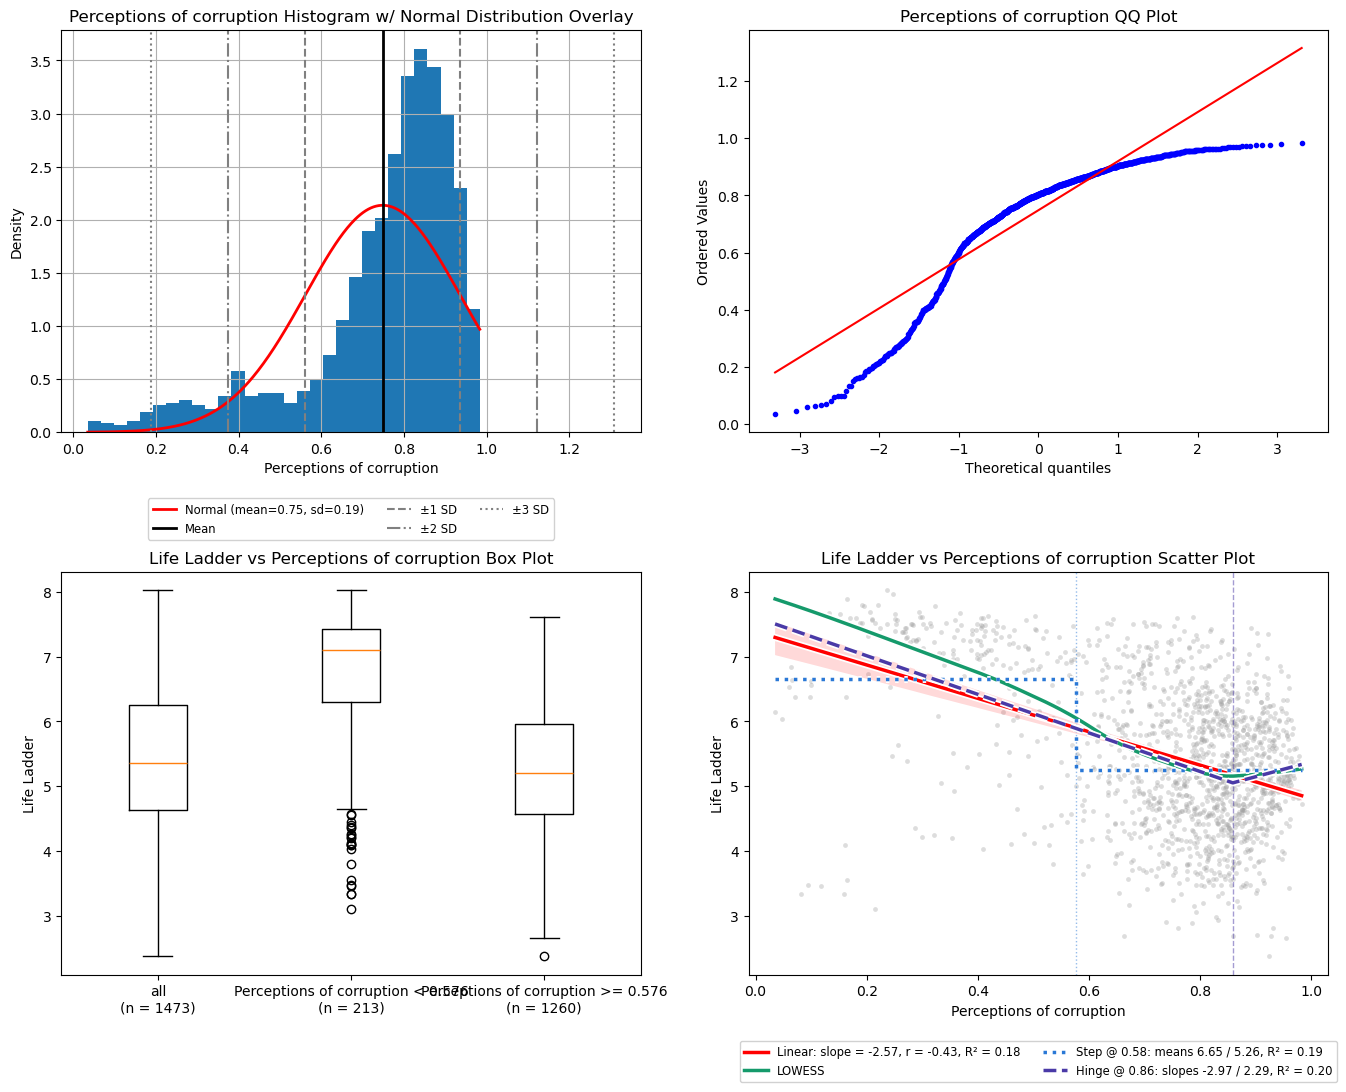

In [5]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['POC']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Highly left skewed (-1.536) and leptokurtic (excess kurtosis 2.006).** Half the values sit between 0.691 and 0.873, crowded just below the max of 0.983, with a long thin tail down to 0.035. The histogram shows the tail as a low plateau from about 0.05 to 0.55.
- **QQ plot:** the low end falls far below the line (long low tail) and the top flattens near 0.98 (values piling up against the top).
- **130 low outliers** below the 0.418 fence, and none above.
- **Negative relationship with Life Ladder:** r = -0.428 (R² 0.18).
- **The relationship is all in the low tail.** LOWESS falls steeply up to about 0.6 and is flat from about 0.75 to 1. The step at 0.58 (means 6.65 / 5.26) reaches R² 0.19 with just an above/below split, slightly above the linear R² of 0.18. The box plot shows the same thing: the 213 rows below 0.576 have a median Life Ladder of about 7.1, vs about 5.2 for the 1,260 rows above.
- The hinge at 0.86 (R² 0.20) turns upward at the top end, which LOWESS does not follow.

#### Special Treatment

- **Do not clip, winsorize or drop the low outliers.** The low tail is where Life Ladder changes, so capping it at the IQR fence would remove the signal.
- **A skew fixing transform is unlikely to help.** It would stretch the crowded top end, which is exactly where LOWESS is flat.
- **Model the shape instead:** a hinge or spline term (steep below a threshold near 0.6, flat above), or an indicator for values below the threshold added alongside the raw value.

## Social Support

In [6]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['SS']['col']], target=train_df[TARGET]))

,Social support
count,1549.0
missing,10
% missing,0.641
mean,0.813
std,0.119
min,0.29
25%,0.753
50%,0.835
75%,0.905
max,0.987


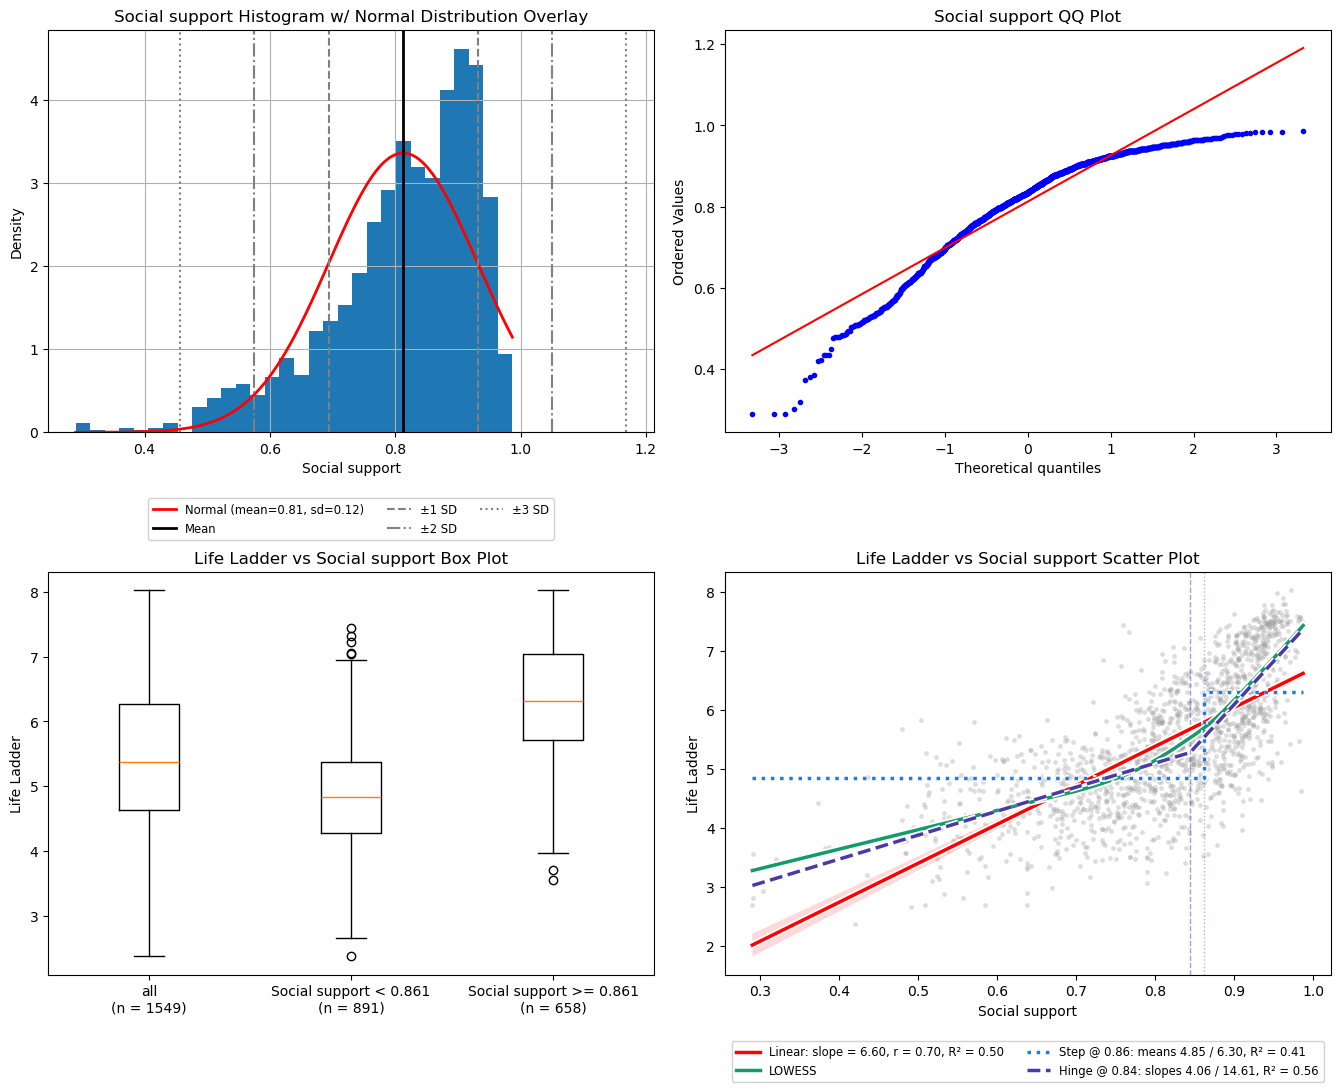

In [7]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['SS']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Highly left skewed (-1.138) and leptokurtic (1.298).** Half the values sit between 0.753 and 0.905, just below the max of 0.987, with a tail down to 0.29.
- **QQ plot:** the low end falls below the line and the top flattens near 0.98 (values piling up against the top).
- **42 low outliers** below the 0.525 fence, and none above. In the scatter plot they follow the LOWESS curve, so they look like part of the trend rather than errors.
- **Strong positive relationship:** r = 0.704 (R² 0.50).
- **Not linear.** LOWESS is shallow below about 0.8 and steep above. The hinge at 0.84 changes the slope from 4.06 to 14.61 and lifts R² from 0.50 to 0.56. The straight line overpredicts Life Ladder in the low tail and underpredicts it at the top.

#### Special Treatment

- **A transform that stretches the top end** (ex logit or Yeo-Johnson), which would reduce the skew and straighten the relationship at the same time.
- **Or a hinge or spline term** near 0.84.
- **Keep the low outliers.** A transform that stretches the top end also compresses the low tail, which reduces their pull on the fit.

## Generosity

In [8]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['G']['col']], target=train_df[TARGET]))

,Generosity
count,1488.0
missing,71
% missing,4.554
mean,0.0
std,0.163
min,-0.335
25%,-0.113
50%,-0.025
75%,0.091
max,0.698


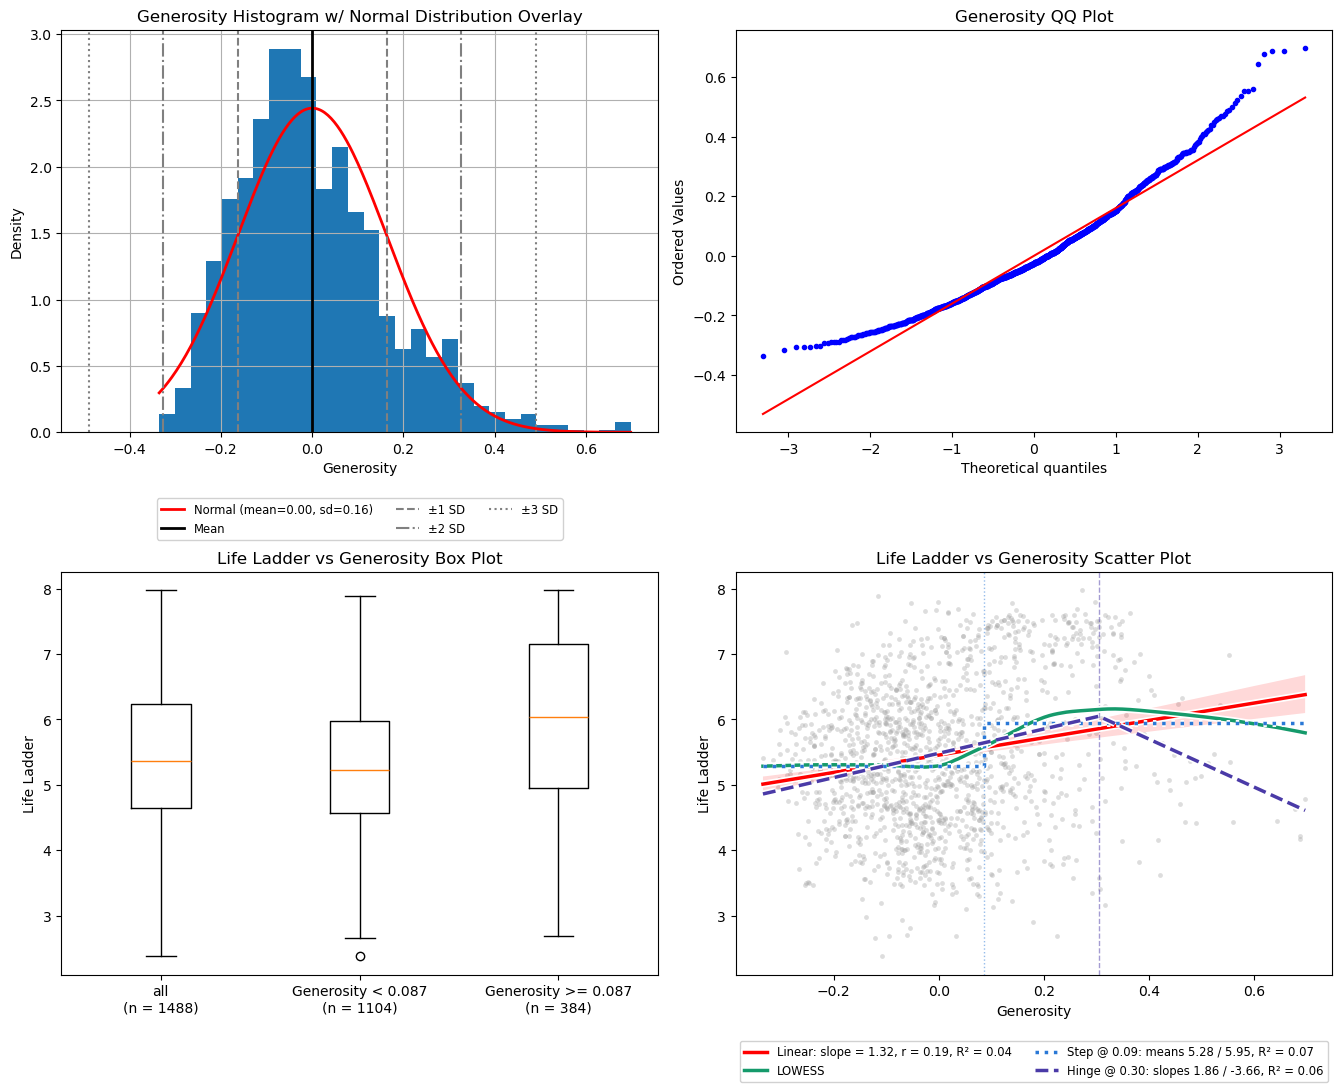

In [9]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['G']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Centered on 0** (mean 0.0, median -0.025) and the only attribute with negative values (min -0.335, max 0.698).
- **Moderately right skewed (0.828), mesokurtic (0.945).** The histogram peaks just below 0 with a long right tail.
- **QQ plot:** the high end rises above the line (long right tail) and the low end sits above it too (short left tail).
- **31 high outliers** above the 0.397 fence, and none below.
- **Weakest relationship with Life Ladder:** r = 0.195 (R² 0.04).
- **Rises, then falls.** LOWESS is flat below about 0.05, climbs to about 0.3, then turns down. The hinge at 0.30 flips the slope from 1.86 to -3.66, but only reaches R² 0.06. The downturn rests on the few rows in the right tail.

#### Special Treatment

- **Log and Box-Cox are not possible** because of the negative values. Yeo-Johnson can handle them if the skew needs fixing.
- **The high outliers** drive the downturn. Capping the top tail is worth testing.
- **Low value overall:** a candidate to drop, or to leave in only if it improves the model.

## Healthy Life Expectancy at Birth

In [10]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['HLEAB']['col']], target=train_df[TARGET]))

,Healthy life expectancy at birth
count,1522.0
missing,37
% missing,2.373
mean,63.332
std,7.478
min,32.3
25%,58.34
50%,65.18
75%,68.535
max,77.1


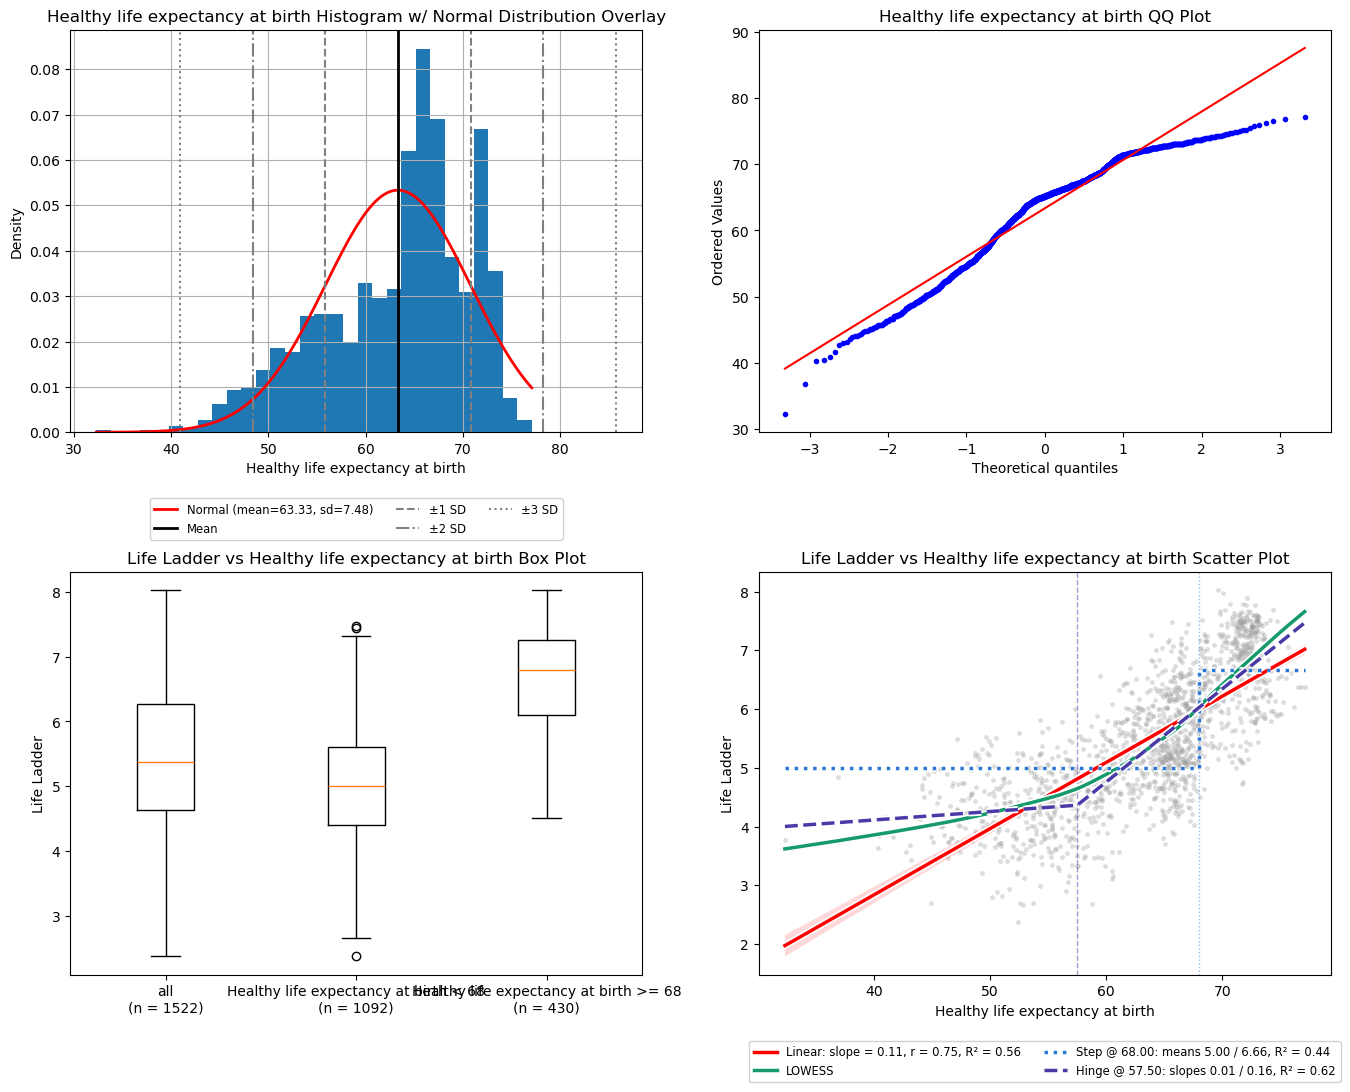

In [11]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['HLEAB']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately left skewed (-0.723), mesokurtic (-0.093).** The histogram has a broad lower shoulder (about 45 to 62) and a tall peak (about 64 to 74).
- **QQ plot:** the low end falls below the line and the top flattens around 74 to 77 (values piling up against the top).
- **7 low outliers** below the 43.048 fence (min 32.3), and none above.
- **Strong positive relationship:** r = 0.751 (R² 0.56).
- **Flat, then steep.** LOWESS is nearly flat below about 57 and steep above. The hinge at 57.5 has slopes of 0.01 then 0.16 and lifts R² from 0.56 to 0.62, so below about 57.5 this attribute says almost nothing about Life Ladder.
- The step at 68 alone gives means of 5.00 / 6.66 (R² 0.44). The box plot shows the same split: the 430 rows at or above 68 have a median Life Ladder of about 6.8, vs about 5.0 for the 1,092 rows below.

#### Special Treatment

- **A hinge or spline term** near 57.5, which matches the flat-then-steep shape directly.
- **Or a transform that stretches the top end** (ex Yeo-Johnson or squaring).

## Negative Affect

In [12]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['NA']['col']], target=train_df[TARGET]))

,Negative affect
count,1545.0
missing,14
% missing,0.898
mean,0.268
std,0.084
min,0.083
25%,0.206
50%,0.258
75%,0.319
max,0.705


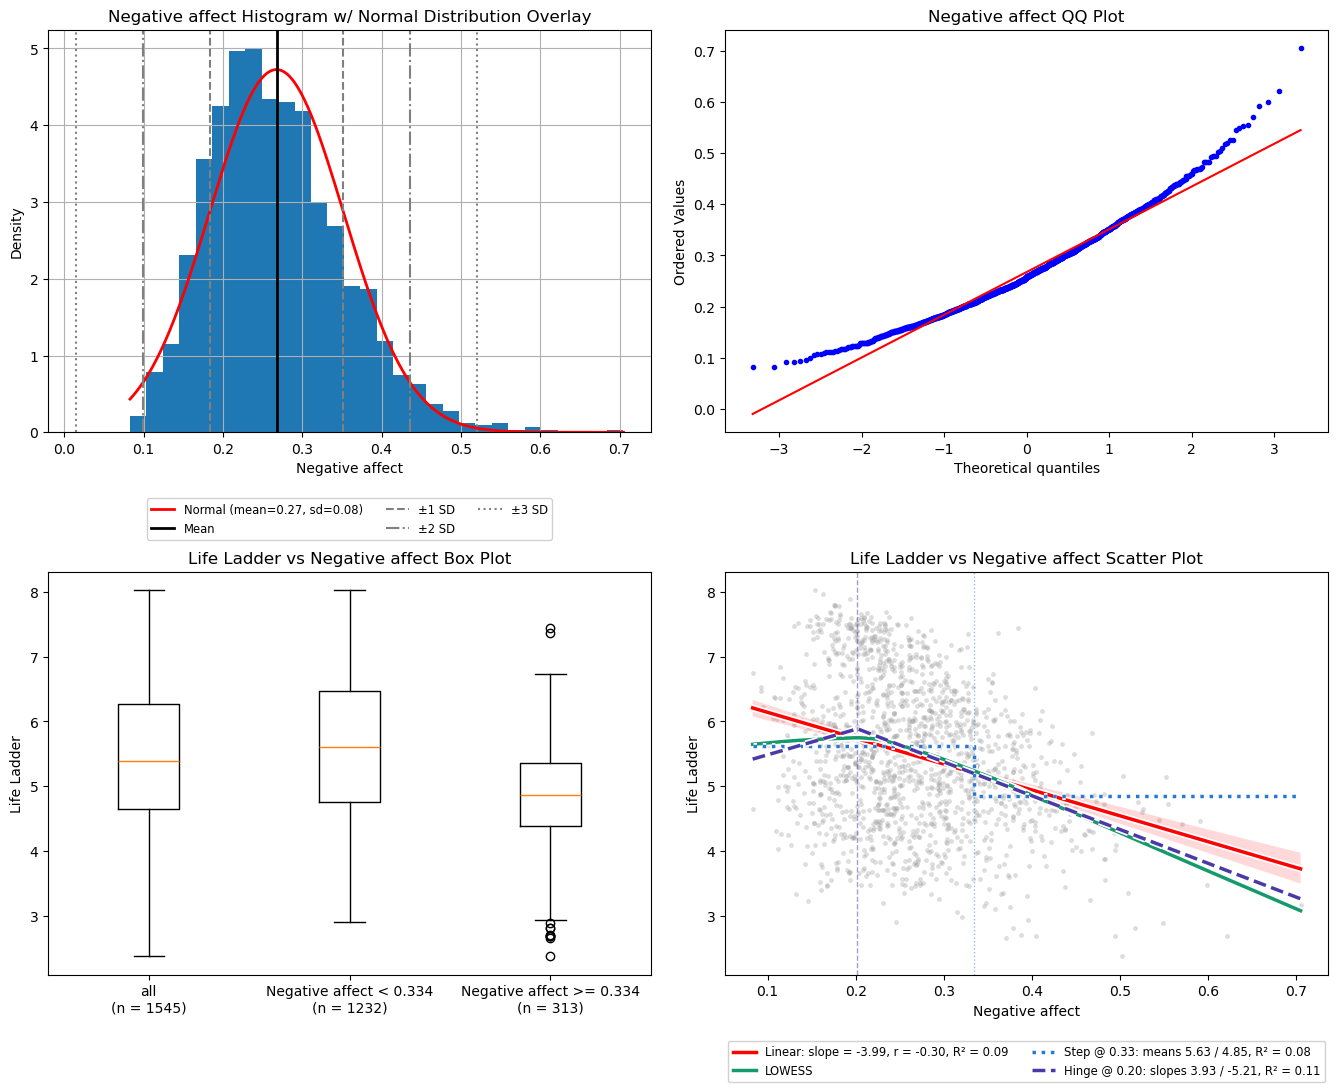

In [13]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['NA']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately right skewed (0.696), mesokurtic (0.801).** Values bunch at the low end (min 0.083) with a long right tail up to 0.705.
- **QQ plot:** the low end sits above the line (short low tail) and the high end rises above it (long high tail).
- **20 high outliers** above the 0.489 fence, and none below.
- **Weak negative relationship:** r = -0.302 (R² 0.09).
- **Only matters once it is high.** LOWESS is flat, even slightly rising, up to about 0.2, then falls. The hinge at 0.20 flips the slope from 3.93 to -5.21 (R² 0.11 vs 0.09).

#### Special Treatment

- **Avoid log or similar skew fixing transforms.** They compress the high tail, which is where Life Ladder changes.
- **A hinge term** `max(0, x - t)` with t near 0.20.
- **Keep the high outliers.** They sit in the part of the range that carries the signal.

## Freedom to Make Life Choices

In [14]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['FTMLC']['col']], target=train_df[TARGET]))

,Freedom to make life choices
count,1537.0
missing,22
% missing,1.411
mean,0.742
std,0.142
min,0.26
25%,0.646
50%,0.763
75%,0.855
max,0.985


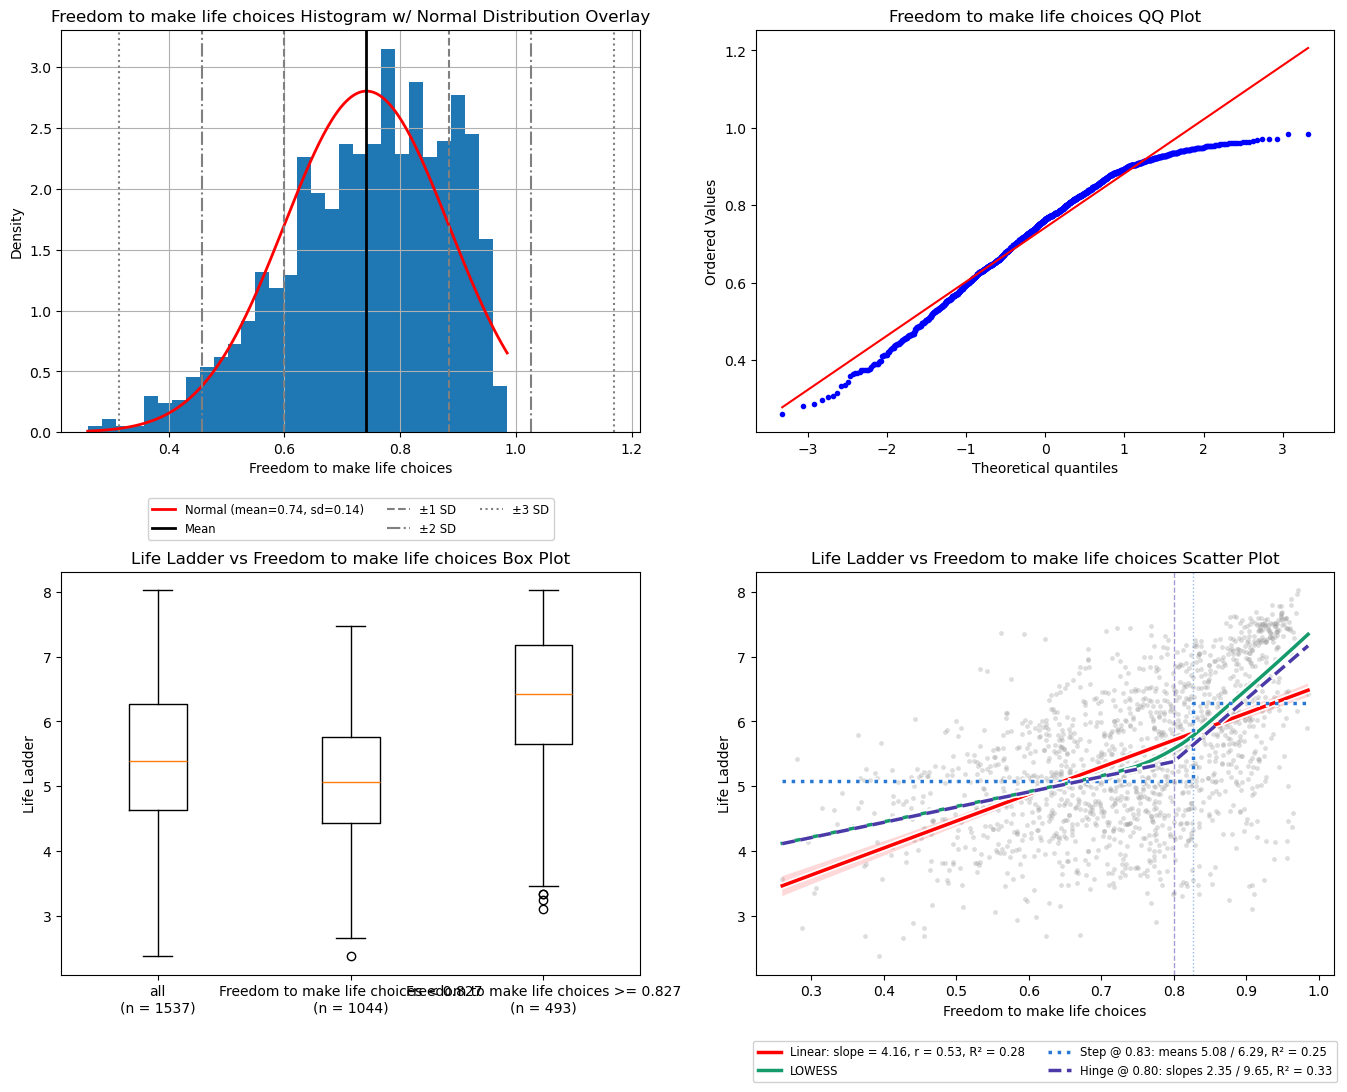

In [15]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['FTMLC']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately left skewed (-0.606), mesokurtic (-0.158).** Values crowd from about 0.85 up to the max of 0.985.
- **QQ plot:** the low end falls below the line and the top flattens (values piling up against the top).
- **8 low outliers** below the 0.333 fence, and none above.
- **Moderate positive relationship:** r = 0.53 (R² 0.28).
- **Not linear.** LOWESS is shallow below about 0.8 and steep above. The hinge at 0.80 changes the slope from 2.35 to 9.65 and lifts R² from 0.28 to 0.33. The step at 0.83 gives means of 5.08 / 6.29.

#### Special Treatment

- **A transform that stretches the top end** (ex `-log(1 - x)` or logit).
- **Or a hinge or spline term** near 0.80.

## Positive Affect

In [16]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['PA']['col']], target=train_df[TARGET]))

,Positive affect
count,1542.0
missing,17
% missing,1.09
mean,0.709
std,0.108
min,0.322
25%,0.623
50%,0.721
75%,0.798
max,0.944


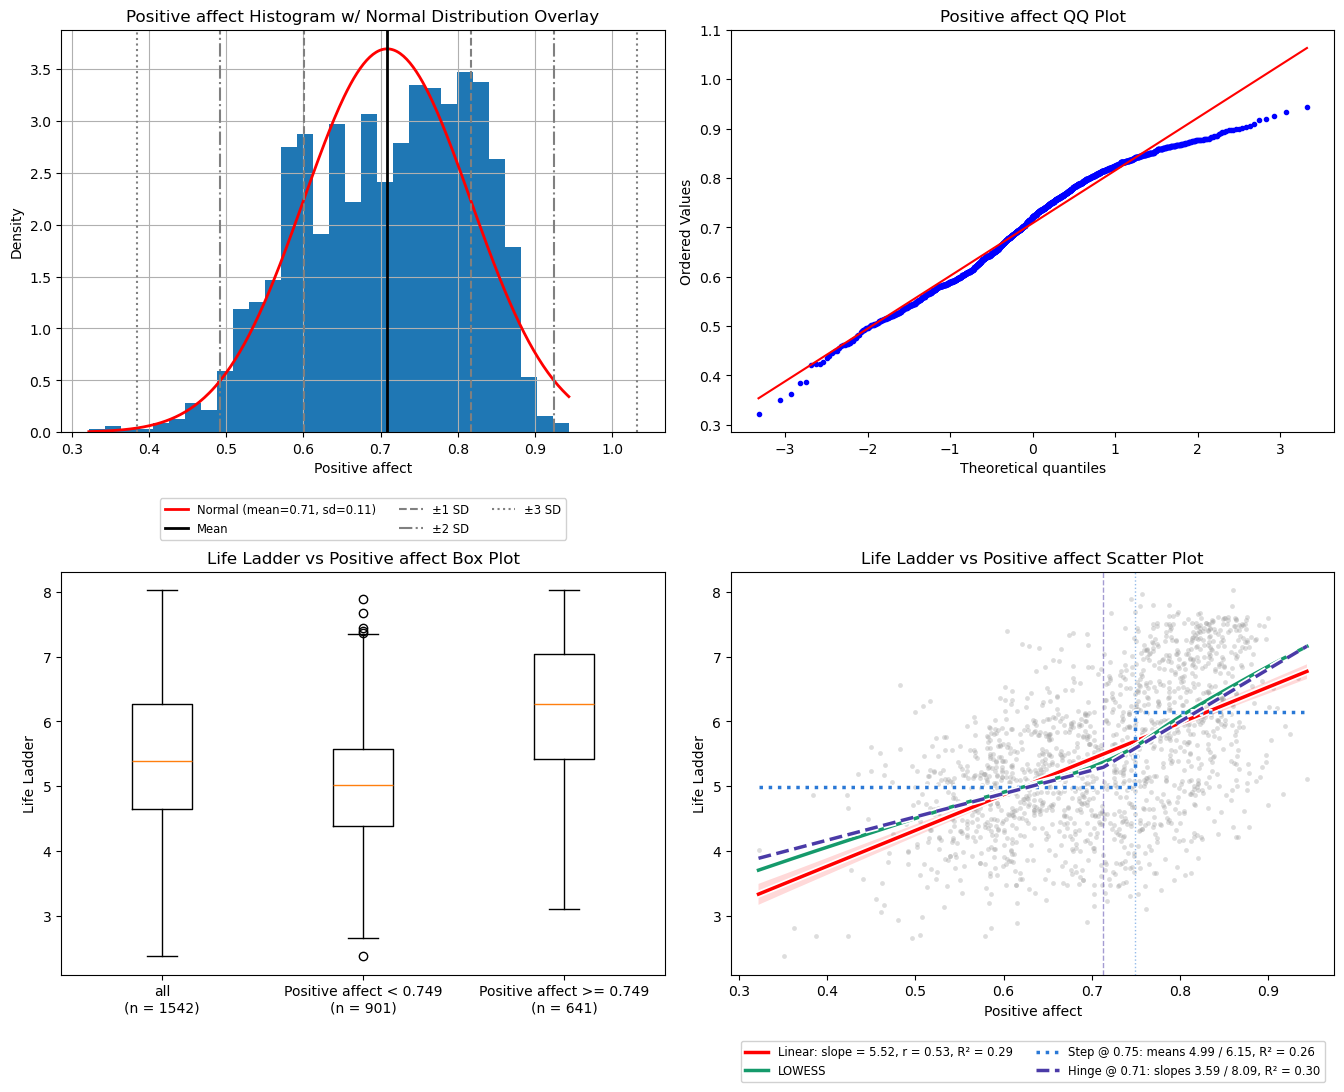

In [17]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['PA']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.348), mesokurtic (-0.607).** The histogram is broad and flat topped, with a possible second peak near 0.8.
- **QQ plot:** close to the line, with a slight flattening at the top (short high tail).
- Only **2 low outliers** below the 0.36 fence.
- **Moderate positive relationship:** r = 0.535 (R² 0.29).
- **Close to linear.** LOWESS steepens slightly above about 0.71. The hinge there (slopes 3.59 / 8.09) only lifts R² from 0.29 to 0.30.

#### Special Treatment

- **None needed.** The distribution is close to normal and the relationship is close to linear.

## Log GDP per Capita

In [18]:
display(STATISTICS.statistics_df(series=train_df[COLUMNS['LGDP']['col']], target=train_df[TARGET]))

,Log GDP per capita
count,1533.0
missing,26
% missing,1.668
mean,9.363
std,1.16
min,6.635
25%,8.46
50%,9.456
75%,10.332
max,11.648


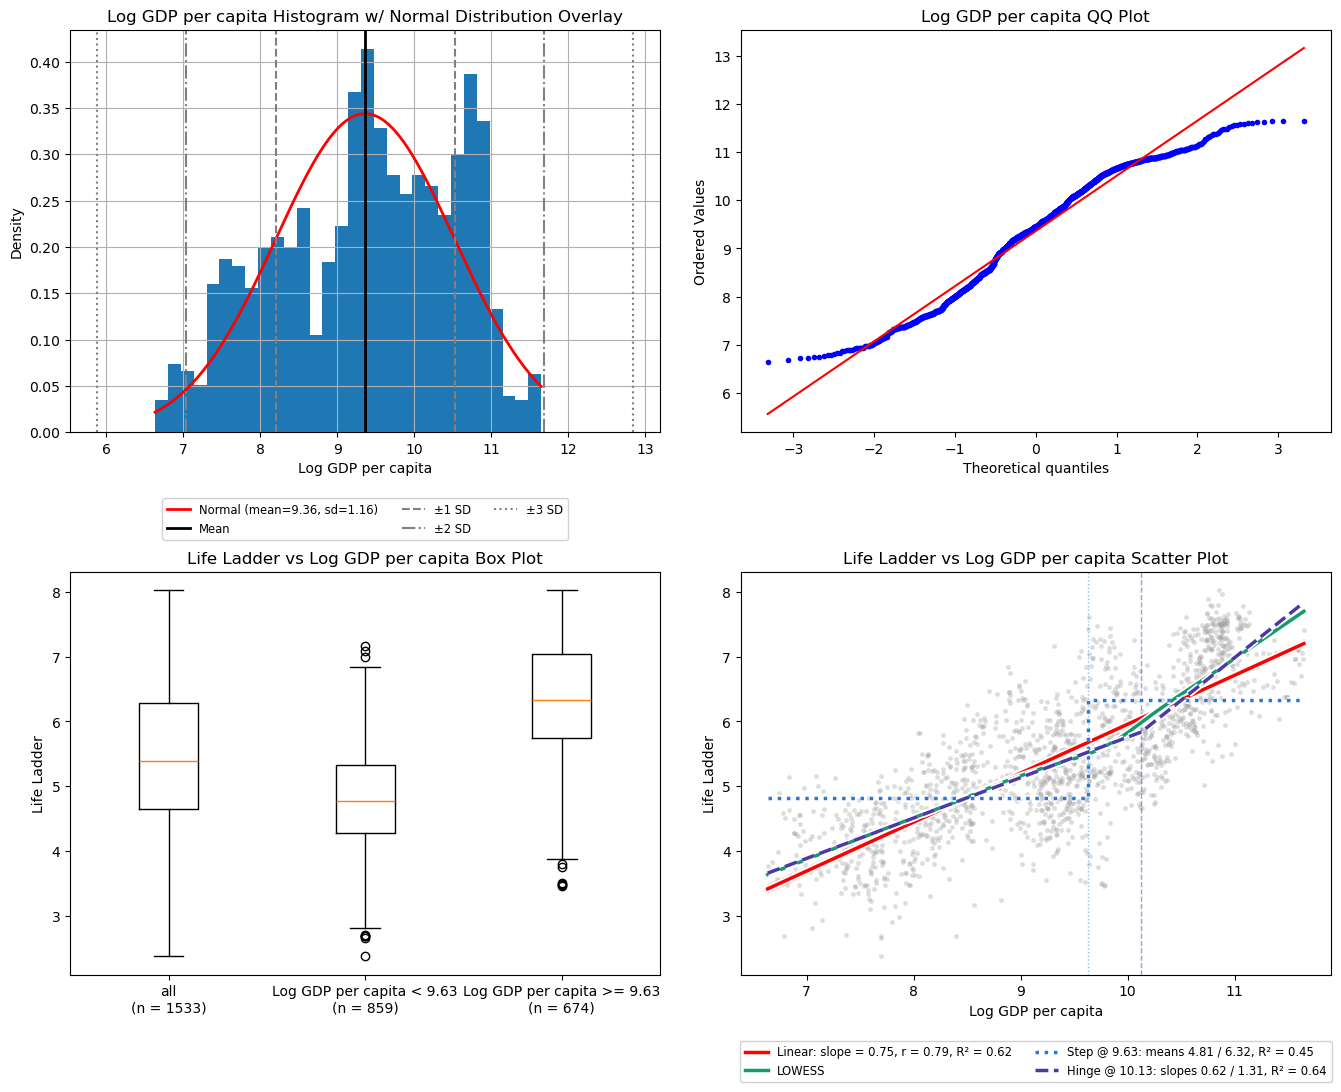

In [19]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['LGDP']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Already log transformed,** per the column name.
- **Roughly symmetric (-0.292), mesokurtic (-0.858, close to the platykurtic cutoff of -1).** The histogram is broad with several peaks (about 7.5, 9.3 and 10.8).
- **QQ plot:** both ends turn back toward the middle (short tails), since the range is compact (6.635 to 11.648).
- **No outliers** on either side.
- **Strongest relationship with Life Ladder:** r = 0.787 (R² 0.62).
- **Close to linear.** LOWESS tracks the red line, with a slight steepening above about 10. The hinge at 10.13 (slopes 0.62 / 1.31) only lifts R² from 0.62 to 0.64.

#### Special Treatment

- **None needed, and do not log it again.** A mild hinge near 10 is optional if it improves the model.